In [39]:
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt

from cadu import iter_packets, packet_apid

In [40]:
CADU_DIR = Path("cadus")
IDLE_APID = 0x7FF
TOP_N = 15

In [41]:
def count_apids(path: Path, packets: Counter[int], sizes: Counter[int]) -> None:
    """Tally the APIDs of one dump."""
    for _, packet in iter_packets(path):
        apid = packet_apid(packet)
        packets[apid] += 1
        sizes[apid] += len(packet)

processed proba2_dump(1).cadu
processed proba2_dump(10).cadu
processed proba2_dump(11).cadu
processed proba2_dump(12).cadu
processed proba2_dump(2).cadu
processed proba2_dump(3).cadu
processed proba2_dump(4).cadu
processed proba2_dump(5).cadu
processed proba2_dump(6).cadu
processed proba2_dump(7).cadu
processed proba2_dump(8).cadu
processed proba2_dump(9).cadu
processed proba2_dump.cadu
APID    2 (0x002):    18399 packets,     3.65 MB
APID   22 (0x016):    11186 packets,     8.56 MB
APID   18 (0x012):     5025 packets,     1.72 MB
APID   20 (0x014):     4240 packets,   231.86 MB
APID   14 (0x00E):     1738 packets,     0.04 MB
APID   21 (0x015):      697 packets,     1.15 MB
APID    8 (0x008):      599 packets,     0.03 MB
APID   11 (0x00B):      131 packets,     0.01 MB
APID  132 (0x084):       92 packets,     0.03 MB
APID  133 (0x085):       91 packets,     0.03 MB
APID  130 (0x082):       58 packets,     1.77 MB
APID    0 (0x000):       27 packets,     0.00 MB
APID  131 (0x083):    

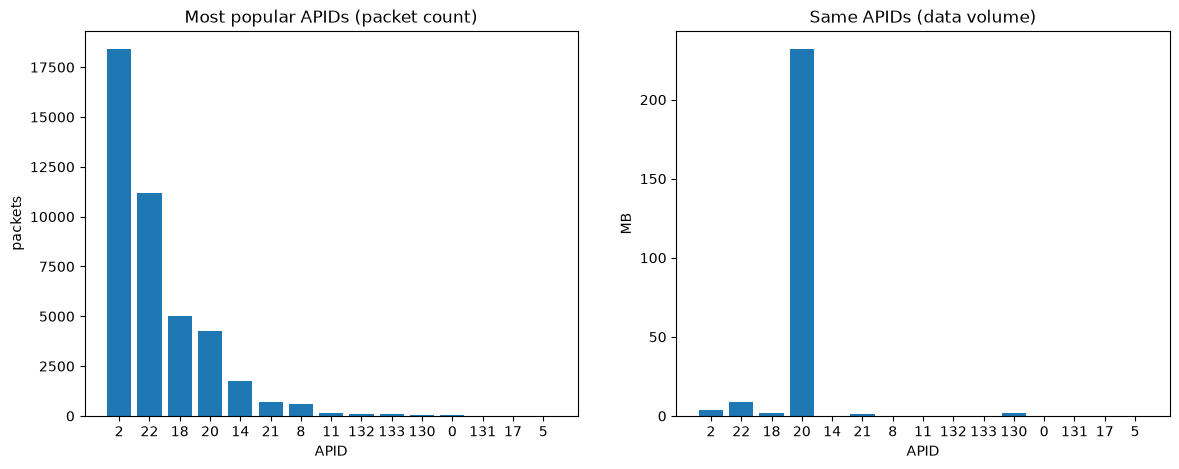

In [42]:
packets: Counter[int] = Counter()
sizes: Counter[int] = Counter()
for path in sorted(CADU_DIR.glob("*.cadu")):
    count_apids(path, packets, sizes)
    print(f"processed {path.name}")

packets.pop(IDLE_APID, None)
top = packets.most_common(TOP_N)
for apid, count in top:
    print(f"APID {apid:4d} (0x{apid:03X}): {count:8d} packets, {sizes[apid] / 1e6:8.2f} MB")

fig, (ax_count, ax_size) = plt.subplots(1, 2, figsize=(14, 5))
labels = [str(apid) for apid, _ in top]
ax_count.bar(labels, [count for _, count in top])
ax_count.set(title="Most popular APIDs (packet count)", xlabel="APID", ylabel="packets")
ax_size.bar(labels, [sizes[apid] / 1e6 for apid, _ in top])
ax_size.set(title="Same APIDs (data volume)", xlabel="APID", ylabel="MB")
plt.show()

In [43]:
# The text segments are records like "F622387446530.1996918 0.000000000 1 ...": an F, a long number, then columns. The
# number is padded with spaces when the second of the week is short ("F622379 12790.0000518 ..."), and the column after
# it can be negative.
TEXT_START = re.compile(rb"F\d[\d ]{10,}\.\d+[ -]")
MIN_PRINTABLE = 0.9  # fraction of printable characters needed for a match to count as a text segment


def printable_fraction(data: bytes) -> float:
    return sum(32 <= b < 127 or b in (9, 10, 13) for b in data) / max(len(data), 1)


segments = []  # (file name, vcid, apid, packet sequence count, offset of the text in the packet, text)
for path in sorted(CADU_DIR.glob("*.cadu")):
    for vcid, packet in iter_packets(path):
        match = TEXT_START.search(packet)
        if match is None:
            continue
        text = packet[match.start() :].rstrip(b"\x00")
        if printable_fraction(text) < MIN_PRINTABLE:
            continue
        seq = int.from_bytes(packet[2:4]) & 0x3FFF
        segments.append((path.name, vcid, packet_apid(packet), seq, match.start(), text.decode("ascii", "replace")))

segment_apids = Counter(apid for _, _, apid, _, _, _ in segments)
print("APIDs of the text segments:", segment_apids.most_common())

APIDs of the text segments: [(18, 4898)]


In [44]:
# A handful of one-off hits come from packets that were reassembled across lost frames (their lengths are absurd),
# the APID that really carries the text dominates.
text_apid, _ = segment_apids.most_common(1)[0]
text_segments = [s for s in segments if s[2] == text_apid]

print(f"APID {text_apid}: {len(text_segments)} segments")
print("packet lengths:", Counter(len(text) + offset for _, _, _, _, offset, text in text_segments).most_common(5))
print("text offsets in packet:", Counter(offset for _, _, _, _, offset, _ in text_segments).most_common(5))
print("virtual channels:", Counter(vcid for _, vcid, _, _, _, _ in text_segments))
print("record types (first two characters):", Counter(text[:2] for *_, text in text_segments).most_common())
print("segments per file:", Counter(name for name, *_ in text_segments))

APID 18: 4898 segments
packet lengths: [(626, 2441), (73, 2439), (72, 12), (625, 5), (616, 1)]
text offsets in packet: [(24, 4898)]
virtual channels: Counter({2: 4368, 1: 530})
record types (first two characters): [('F4', 2451), ('F6', 2447)]
segments per file: Counter({'proba2_dump(10).cadu': 1358, 'proba2_dump(6).cadu': 1166, 'proba2_dump(8).cadu': 1165, 'proba2_dump(2).cadu': 863, 'proba2_dump(11).cadu': 57, 'proba2_dump(3).cadu': 55, 'proba2_dump(12).cadu': 52, 'proba2_dump(9).cadu': 44, 'proba2_dump.cadu': 42, 'proba2_dump(1).cadu': 32, 'proba2_dump(7).cadu': 30, 'proba2_dump(5).cadu': 18, 'proba2_dump(4).cadu': 16})


In [45]:
shown = set()
for name, vcid, apid, seq, _offset, text in text_segments:
    kind = text[:2]
    if kind not in shown:
        shown.add(kind)
        print(f"--- {name} VC{vcid} APID {apid} seq {seq} ({len(text)} chars)")
        print(text, end="\n\n")

Path("apid_text.txt").write_text(
    "".join(f"# {name} VC{vcid} APID {apid} seq {seq}\n{text}\n" for name, vcid, apid, seq, _, text in text_segments)
)

--- proba2_dump(1).cadu VC1 APID 18 seq 5202 (49 chars)
F482387405780.0182387 193601174  510403879.86E�U

--- proba2_dump(1).cadu VC1 APID 18 seq 5203 (602 chars)
F622387405780.0000718-0.010725522 1         0.00        +0.000    +0.00 30.5 01  2         0.00        +0.000    +0.00 30.5 00  3         0.00        +0.000    +0.00 30.5 01 10         0.00        +0.000    +0.00 30.5 00 19         0.00        +0.000    +0.00 31.1 01 14         0.00        +0.000    +0.00 30.5 00 17         0.00        +0.000    +0.00 31.2 01 24         0.00        +0.000    +0.00 30.5 00 22         0.00        +0.000    +0.00 30.5 00 12  21398752.87 -18890573.230 -4771.39 32.5 1F 32         0.00        +0.000    +0.00 31.6 01  6         0.00        +0.000    +0.00 30.6 01 333�



1812139

In [46]:
# Same way satdump_decode.cpp tells images apart: APID 20 packets of one image share the timestamp in the first
# 6 payload bytes (days since 1958 offset by 18630, then milliseconds). Not every image has its first segment in the
# dumps, so every distinct timestamp counts. Packets with an absurd day count are not image segments.
SWAP_APID = 20
SWAP_TIME_OFFSET_DAYS = 18630
MAX_PLAUSIBLE_DAYS = 1000


def swap_timestamp(packet: bytes) -> int | None:
    days = int.from_bytes(packet[6:8])
    milliseconds = int.from_bytes(packet[8:12])
    if days > MAX_PLAUSIBLE_DAYS:
        return None
    return (SWAP_TIME_OFFSET_DAYS + days) * 86400 + milliseconds // 1000


per_file = {}  # file name -> {"images": set of timestamps, "F4": count, "F6": count}
for path in sorted(CADU_DIR.glob("*.cadu")):
    stats = per_file[path.name] = {"images": set(), "F4": 0, "F6": 0}
    for _, packet in iter_packets(path):
        apid = packet_apid(packet)
        if apid == SWAP_APID:
            if (timestamp := swap_timestamp(packet)) is not None:
                stats["images"].add(timestamp)
        elif apid == text_apid:
            match = TEXT_START.search(packet)
            if match and printable_fraction(packet[match.start() :]) >= MIN_PRINTABLE:
                stats[packet[match.start() : match.start() + 2].decode()] += 1

print(f"{'file':24s} {'images':>6s} {'F4':>5s} {'F6':>5s}")
for name, stats in per_file.items():
    print(f"{name:24s} {len(stats['images']):6d} {stats['F4']:5d} {stats['F6']:5d}")

file                     images    F4    F6
proba2_dump(1).cadu          12    16    16
proba2_dump(10).cadu         43   679   679
proba2_dump(11).cadu         32    29    28
proba2_dump(12).cadu         43    26    26
proba2_dump(2).cadu          10   433   430
proba2_dump(3).cadu          33    27    28
proba2_dump(4).cadu          12     8     8
proba2_dump(5).cadu          21     9     9
proba2_dump(6).cadu          38   583   583
proba2_dump(7).cadu          20    15    15
proba2_dump(8).cadu          42   583   582
proba2_dump(9).cadu          24    22    22
proba2_dump.cadu             33    21    21


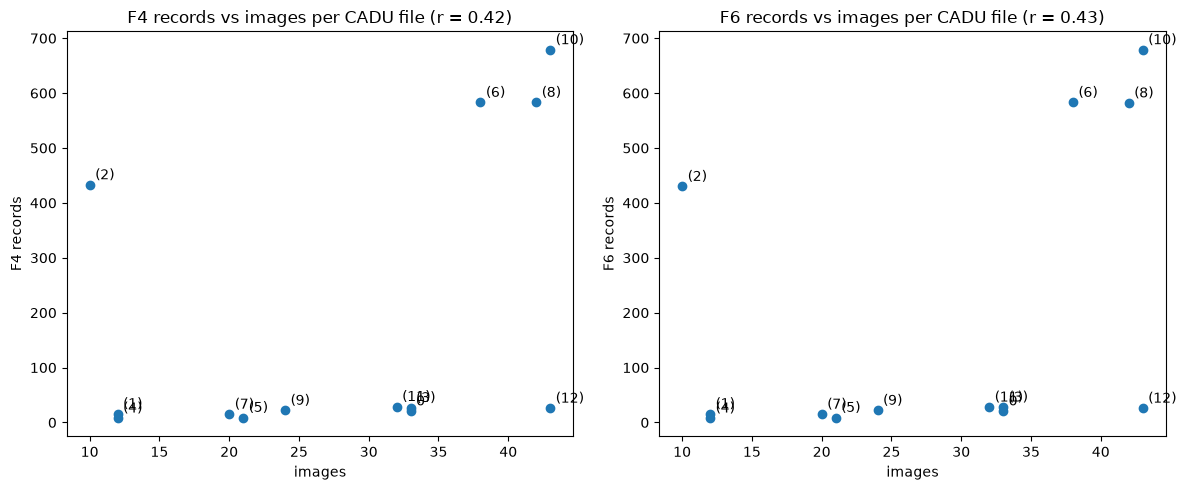

In [47]:
import numpy as np

names = list(per_file)
images = np.array([len(per_file[name]["images"]) for name in names])
f4 = np.array([per_file[name]["F4"] for name in names])
f6 = np.array([per_file[name]["F6"] for name in names])

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
for ax, records, label in ((axes[0], f4, "F4 records"), (axes[1], f6, "F6 records")):
    ax.scatter(images, records)
    for name, x, y in zip(names, images, records, strict=True):
        ax.annotate(
            name.removeprefix("proba2_dump").removesuffix(".cadu") or "0",
            (x, y),
            textcoords="offset points",
            xytext=(4, 4),
        )
    ax.set(
        title=f"{label} vs images per CADU file (r = {np.corrcoef(images, records)[0, 1]:.2f})",
        xlabel="images",
        ylabel=label,
    )
fig.tight_layout()
plt.show()

In [48]:
# Find